# Question 1

In [1]:
try:
    get_ipython().run_line_magic("matplotlib", "widget")
except (ImportError, RuntimeError):
    get_ipython().run_line_magic("matplotlib", "inline")

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

In [2]:
image_path = Path("../a2images/the_berry_farms_sunflower_field.jpeg")
image_bgr = cv2.imread(str(image_path), cv2.IMREAD_REDUCED_COLOR_4)

if image_bgr is None:
    raise FileNotFoundError(f"Could not read image: {image_path.resolve()}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
print(f"Image dimensions: {gray.shape[1]} × {gray.shape[0]} pixels")

Image dimensions: 360 × 360 pixels


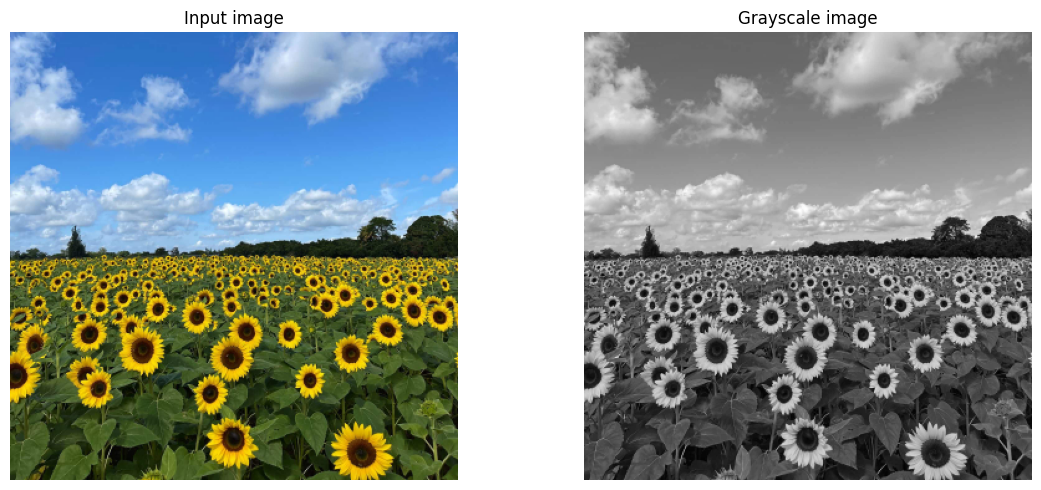

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image_rgb)
axes[0].set_title("Input image")
axes[0].axis("off")
axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale image")
axes[1].axis("off")
plt.tight_layout()

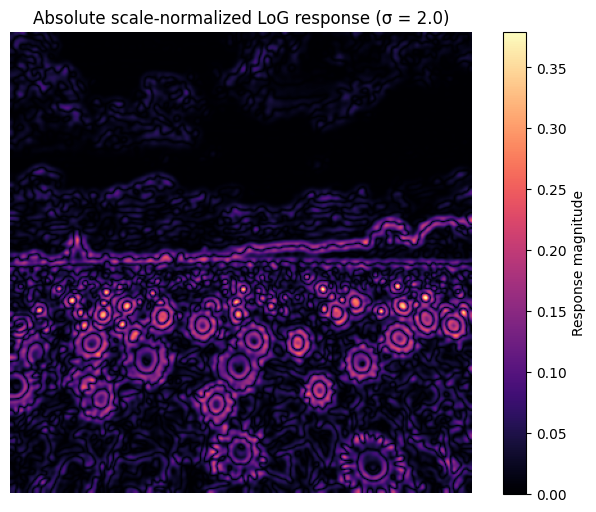

In [4]:
sigma = 2.0
gray_float = gray.astype(np.float32) / 255.0
smoothed = cv2.GaussianBlur(
    gray_float,
    ksize=(0, 0),
    sigmaX=sigma,
    sigmaY=sigma,
)
laplacian = cv2.Laplacian(smoothed, cv2.CV_32F)
log_response = sigma**2 * laplacian

plt.figure(figsize=(8, 6))
plt.imshow(np.abs(log_response), cmap="magma")
plt.title(f"Absolute scale-normalized LoG response (σ = {sigma})")
plt.axis("off")
plt.colorbar(label="Response magnitude")
plt.show()

Scale range: ? = 1.50?12.00 px (18 scales)
Response threshold: 0.2236; detections: 64
Largest detections (x, y, ?, radius, response):
( 187,  341), ?= 5.10, r= 7.21, response=0.2599
( 167,  338), ?= 5.10, r= 7.21, response=0.2460
( 300,  344), ?= 5.10, r= 7.21, response=0.2430
(   0,  291), ?= 4.51, r= 6.38, response=0.2635
( 164,  325), ?= 4.51, r= 6.38, response=0.2526
( 268,  348), ?= 4.51, r= 6.38, response=0.2520
( 190,  253), ?= 4.51, r= 6.38, response=0.2420
( 295,  327), ?= 4.51, r= 6.38, response=0.2279
( 112,  269), ?= 3.99, r= 5.64, response=0.2916
(  13,  286), ?= 3.99, r= 5.64, response=0.2752


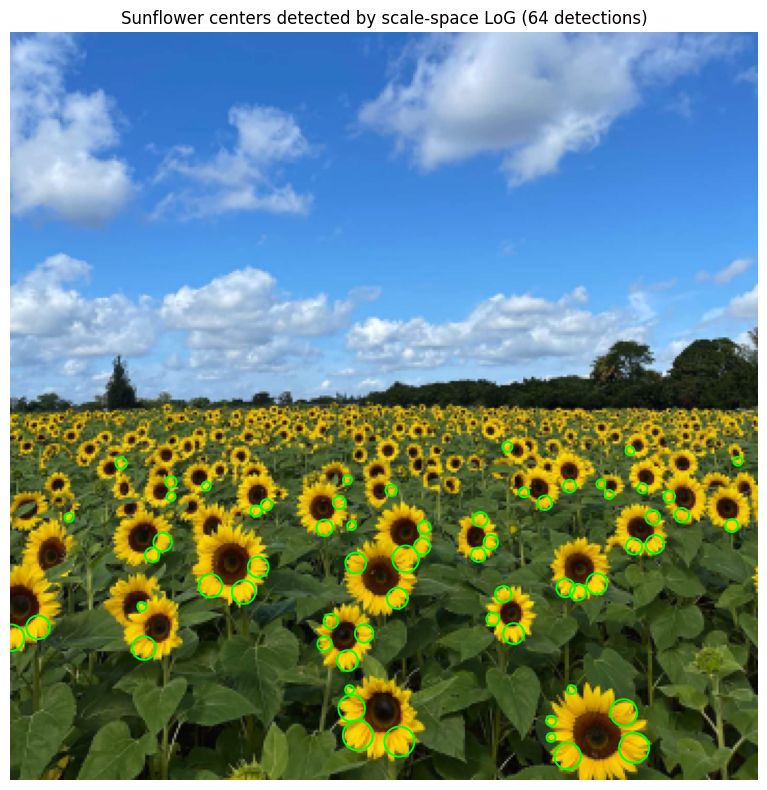

In [5]:
# Q1: Search the scale-normalized LoG volume for extrema in x, y, and scale.
# Report the scale interval and largest detected flower-center circles.
from scipy.ndimage import maximum_filter

# Search small-to-large flower centers at these scales (pixels in the reduced image).
sigmas = np.geomspace(1.5, 12.0, 18)
responses = []
for scale in sigmas:
    blurred = cv2.GaussianBlur(gray_float, (0, 0), sigmaX=float(scale), sigmaY=float(scale))
    # Sunflower centers are darker than their surroundings, so use -LoG.
    response = -(float(scale) ** 2) * cv2.Laplacian(blurred, cv2.CV_32F)
    responses.append(response)
scale_space = np.stack(responses, axis=0)

# Keep maxima across x, y and neighboring scales; suppress image-border artifacts.
local_max = scale_space == maximum_filter(scale_space, size=(3, 5, 5), mode="nearest")
positive = scale_space[scale_space > 0]
response_floor = max(float(np.quantile(positive, 0.997)), 0.025) if positive.size else 0.025
candidate_indices = np.argwhere(local_max & (scale_space >= response_floor))
# Restrict detections to the sunflower field and below, excluding sky and distant trees.
candidates = [
    (float(scale_space[k, y, x]), int(x), int(y), float(sigmas[k]), float(np.sqrt(2) * sigmas[k]))
    for k, y, x in candidate_indices
    if y >= int(0.50 * gray.shape[0])
]
candidates.sort(reverse=True)

# Greedy spatial non-maximum suppression keeps one circle per flower center.
detections = []
for score, x, y, scale, radius in candidates:
    if all((x - dx) ** 2 + (y - dy) ** 2 >= (1.4 * max(radius, dr)) ** 2
           for _, dx, dy, _, dr in detections):
        detections.append((score, x, y, scale, radius))
    if len(detections) >= 100:
        break

print(f"Scale range: ? = {sigmas.min():.2f}?{sigmas.max():.2f} px ({len(sigmas)} scales)")
print(f"Response threshold: {response_floor:.4f}; detections: {len(detections)}")
print("Largest detections (x, y, ?, radius, response):")
for score, x, y, scale, radius in sorted(detections, key=lambda item: item[4], reverse=True)[:10]:
    print(f"({x:4d}, {y:4d}), ?={scale:5.2f}, r={radius:5.2f}, response={score:.4f}")

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image_rgb)
for score, x, y, scale, radius in detections:
    ax.add_patch(plt.Circle((x, y), radius, color="lime", fill=False, linewidth=1.4))
ax.set_title(f"Sunflower centers detected by scale-space LoG ({len(detections)} detections)")
ax.axis("off")
plt.tight_layout()
q1_output = Path("../results/question_1")
q1_output.mkdir(parents=True, exist_ok=True)
fig.savefig(q1_output / "sunflower_log_detections.png", dpi=180, bbox_inches="tight")
plt.show()


# Question 2

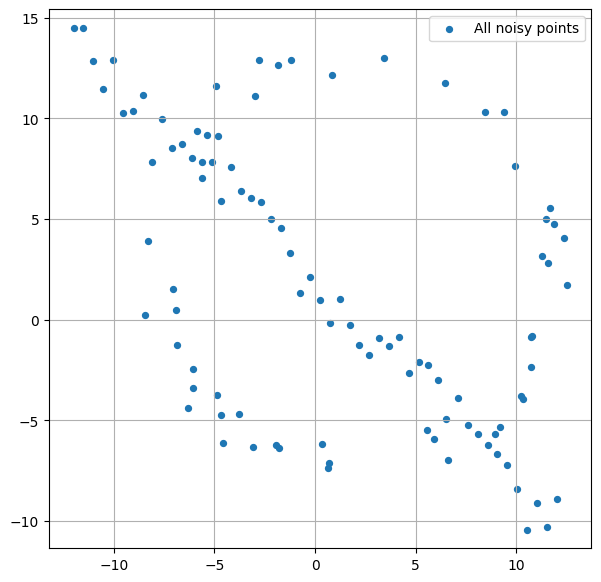

In [6]:
rng = np.random.default_rng(0)
N = 100
half_n = N // 2

# Noisy circle points (ground truth is useful for checking the plot later).
circle_radius_gt = 10.0
circle_center_gt = np.array([2.0, 3.0])
t = rng.uniform(0, 2 * np.pi, half_n)
radial_noise = (circle_radius_gt / 16) * rng.standard_normal(half_n)
X_circle = np.column_stack((
    circle_center_gt[0] + (circle_radius_gt + radial_noise) * np.cos(t),
    circle_center_gt[1] + (circle_radius_gt + radial_noise) * np.sin(t),
))

# Noisy line points.
line_slope_gt, line_intercept_gt = -1.0, 2.0
x_line = np.linspace(-12, 12, half_n)
y_line = line_slope_gt * x_line + line_intercept_gt + rng.standard_normal(half_n)
X_line = np.column_stack((x_line, y_line))
X = np.vstack((X_circle, X_line))

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X[:, 0], X[:, 1], s=18, label="All noisy points")
ax.set_aspect("equal", adjustable="datalim")
ax.legend()
ax.grid(True)
plt.show()

Line: 0.7044 x + 0.7098 y = 1.6010
Consensus points: 49 / 100
Two-point sample indices: [94 61]


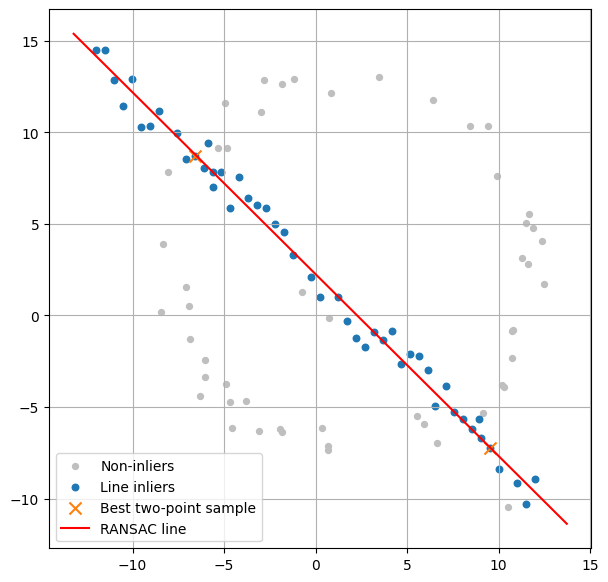

In [7]:
def line_from_two_points(p1, p2):
    """Return (a, b, d) for a unit-normal line a*x + b*y = d."""
    direction = p2 - p1
    length = np.linalg.norm(direction)
    if length < 1e-12:
        return None
    normal = np.array([-direction[1], direction[0]]) / length
    return normal[0], normal[1], float(normal @ p1)


def ransac_line(points, threshold=1.5, min_inliers=35, iterations=2000, seed=0):
    """Find a line with two-point RANSAC; return model, inlier mask, sample."""
    random = np.random.default_rng(seed)
    best_model, best_mask, best_sample = None, None, None
    for _ in range(iterations):
        sample = random.choice(len(points), size=2, replace=False)
        model = line_from_two_points(points[sample[0]], points[sample[1]])
        if model is None:
            continue
        a, b, d = model
        errors = np.abs(points @ np.array([a, b]) - d)
        mask = errors < threshold
        if best_mask is None or mask.sum() > best_mask.sum():
            best_model, best_mask, best_sample = model, mask, sample

    if best_mask is None or best_mask.sum() < min_inliers:
        raise RuntimeError("RANSAC did not find a line with enough consensus points.")

    # Refit using all consensus points with total least squares, preserving ||[a,b]||=1.
    inlier_points = points[best_mask]
    centroid = inlier_points.mean(axis=0)
    _, _, vh = np.linalg.svd(inlier_points - centroid, full_matrices=False)
    normal = vh[-1]
    d = float(normal @ centroid)
    return (float(normal[0]), float(normal[1]), d), best_mask, best_sample

line_model, line_inliers, line_sample = ransac_line(X, threshold=1.0, min_inliers=35)
a, b, d = line_model
print(f"Line: {a:.4f} x + {b:.4f} y = {d:.4f}")
print(f"Consensus points: {line_inliers.sum()} / {len(X)}")
print(f"Two-point sample indices: {line_sample}")

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X[~line_inliers, 0], X[~line_inliers, 1], s=18, color="0.75", label="Non-inliers")
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], s=22, label="Line inliers")
sample_points = X[line_sample]
ax.scatter(sample_points[:, 0], sample_points[:, 1], s=75, marker="x", label="Best two-point sample")
x_limits = np.array(ax.get_xlim())
if abs(b) > 1e-8:
    ax.plot(x_limits, (d - a * x_limits) / b, "r-", label="RANSAC line")
else:
    x_value = d / a
    ax.axvline(x_value, color="r", label="RANSAC line")
ax.set_aspect("equal", adjustable="datalim")
ax.legend()
ax.grid(True)
plt.show()

Circle: center=(2.186, 2.739), radius=9.959
Circle consensus: 39 / 51 line-removed points
Three-point sample indices in line-removed set: [28  5 29]


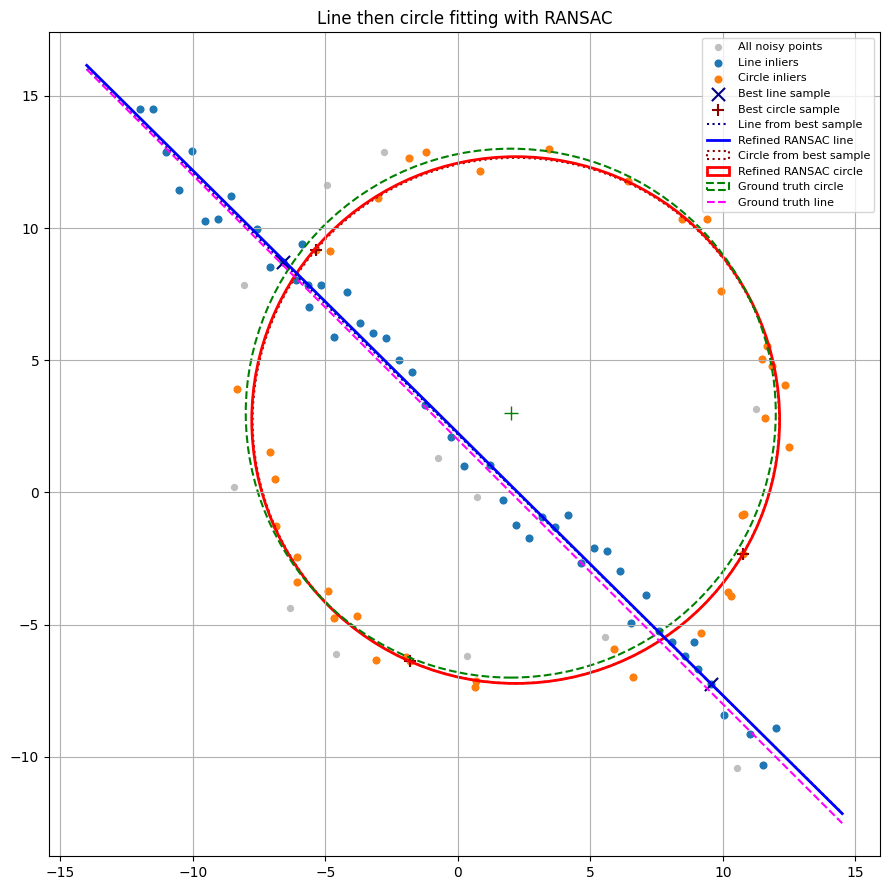

In [8]:
# Q2(b): Remove the line consensus, then use three-point RANSAC and radial error to find the circle.
# Q2(c): Plot the best sample hypotheses, refined models, ground truth, and both inlier sets.
def circle_from_three_points(points):
    """Return (cx, cy, radius) for a 3-point circle, or None if degenerate."""
    p1, p2, p3 = np.asarray(points, dtype=float)
    matrix = 2.0 * np.vstack((p2 - p1, p3 - p1))
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    if abs(np.linalg.det(matrix)) < 1e-8:
        return None
    center = np.linalg.solve(matrix, rhs)
    radius = float(np.linalg.norm(center - p1))
    if not np.isfinite(radius) or radius <= 0:
        return None
    return float(center[0]), float(center[1]), radius


def ransac_circle(points, threshold=0.8, min_inliers=38, iterations=4000, seed=1):
    """Three-point circle RANSAC with radial-error consensus."""
    random = np.random.default_rng(seed)
    best_model, best_mask, best_sample = None, None, None
    for _ in range(iterations):
        sample = random.choice(len(points), size=3, replace=False)
        model = circle_from_three_points(points[sample])
        if model is None:
            continue
        cx, cy, radius = model
        errors = np.abs(np.linalg.norm(points - np.array([cx, cy]), axis=1) - radius)
        mask = errors < threshold
        if best_mask is None or mask.sum() > best_mask.sum():
            best_model, best_mask, best_sample = model, mask, sample
    if best_mask is None or best_mask.sum() < min_inliers:
        raise RuntimeError("RANSAC did not find a circle with enough consensus points.")

    # Refine center and radius by minimizing radial residuals over the consensus set.
    from scipy.optimize import least_squares
    inlier_points = points[best_mask]
    fit = least_squares(
        lambda params: np.linalg.norm(inlier_points - params[:2], axis=1) - params[2],
        x0=np.asarray(best_model),
        bounds=([-np.inf, -np.inf, 1e-8], [np.inf, np.inf, np.inf]),
    )
    cx, cy, radius = fit.x
    return (float(cx), float(cy), float(radius)), best_mask, best_sample, best_model

circle_points = X[~line_inliers]
circle_model, circle_inliers_local, circle_sample, circle_sample_model = ransac_circle(
    circle_points, threshold=0.8, min_inliers=30, iterations=4000, seed=1
)
circle_inliers = np.zeros(len(X), dtype=bool)
circle_inliers[np.flatnonzero(~line_inliers)[circle_inliers_local]] = True
cx, cy, radius = circle_model
print(f"Circle: center=({cx:.3f}, {cy:.3f}), radius={radius:.3f}")
print(f"Circle consensus: {circle_inliers.sum()} / {len(circle_points)} line-removed points")
print(f"Three-point sample indices in line-removed set: {circle_sample}")

# Sample-derived models are drawn separately from the consensus-refined models.
line_sample_model = line_from_two_points(X[line_sample[0]], X[line_sample[1]])
def draw_line(ax, model, x_values, **kwargs):
    la, lb, ld = model
    if abs(lb) > 1e-8:
        ax.plot(x_values, (ld - la * x_values) / lb, **kwargs)
    else:
        ax.axvline(ld / la, **kwargs)

fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(X[:, 0], X[:, 1], s=18, color="0.75", label="All noisy points")
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], s=23, color="tab:blue", label="Line inliers")
ax.scatter(X[circle_inliers, 0], X[circle_inliers, 1], s=23, color="tab:orange", label="Circle inliers")
ax.scatter(X[line_sample, 0], X[line_sample, 1], s=90, marker="x", color="navy", label="Best line sample")
original_circle_points = circle_points[circle_sample]
ax.scatter(original_circle_points[:, 0], original_circle_points[:, 1], s=85, marker="+", color="darkred", label="Best circle sample")
x_values = np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 300)
draw_line(ax, line_sample_model, x_values, color="navy", linestyle=":", linewidth=1.5, label="Line from best sample")
draw_line(ax, line_model, x_values, color="blue", linewidth=2, label="Refined RANSAC line")
# The sample circle can be extremely large for near-collinear triplets; omit only if off-plot.
scx, scy, sr = circle_sample_model
if sr < 100:
    ax.add_patch(plt.Circle((scx, scy), sr, fill=False, color="darkred", linestyle=":", linewidth=1.5, label="Circle from best sample"))
ax.add_patch(plt.Circle((cx, cy), radius, fill=False, color="red", linewidth=2, label="Refined RANSAC circle"))
ax.add_patch(plt.Circle(tuple(circle_center_gt), circle_radius_gt, fill=False, color="green", linestyle="--", linewidth=1.5, label="Ground truth circle"))
ax.plot(*circle_center_gt, "+", color="green", markersize=10)
# Ground-truth line is included for visual comparison.
ax.plot(x_values, line_slope_gt * x_values + line_intercept_gt, color="magenta", linestyle="--", linewidth=1.5, label="Ground truth line")
ax.set_aspect("equal", adjustable="datalim")
ax.set_title("Line then circle fitting with RANSAC")
ax.grid(True)
ax.legend(fontsize=8, loc="best")
plt.tight_layout()
q2_output = Path("../results/question_2")
q2_output.mkdir(parents=True, exist_ok=True)
fig.savefig(q2_output / "line_circle_ransac.png", dpi=180, bbox_inches="tight")
plt.show()


In [9]:
# Q2(d): Fitting the circle first can work with a suitable threshold and consensus size.
# However, line points may support large-radius circle hypotheses, so fitting the line first
# usually leaves a cleaner set for circle estimation. The order can be reversed when each
# model is validated by its consensus; neither order is guaranteed for every noise level.


# Question 3

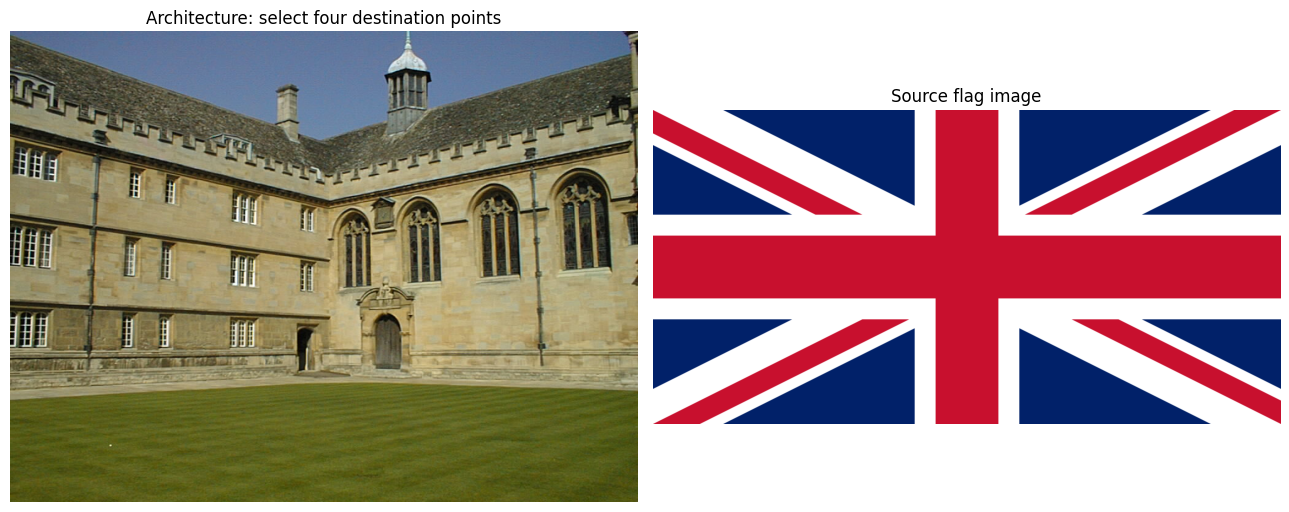

In [10]:
architecture_path = Path("../a2images/wadham.jpg")
flag_path = Path("../a2images/flag.png")
architecture_bgr = cv2.imread(str(architecture_path), cv2.IMREAD_COLOR)
flag_bgra = cv2.imread(str(flag_path), cv2.IMREAD_UNCHANGED)
if architecture_bgr is None or flag_bgra is None:
    raise FileNotFoundError("Could not load wadham.jpg and flag.png from ../a2images")
architecture_rgb = cv2.cvtColor(architecture_bgr, cv2.COLOR_BGR2RGB)
flag_rgb = cv2.cvtColor(flag_bgra[:, :, :3], cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].imshow(architecture_rgb)
axes[0].set_title("Architecture: select four destination points")
axes[0].axis("off")
axes[1].imshow(flag_rgb)
axes[1].set_title("Source flag image")
axes[1].axis("off")
plt.tight_layout()
plt.show()

In [11]:
# Click four planar-surface corners in the left image, in clockwise order.
# Click the four corners in the displayed image, then press Enter.
backend_name = plt.get_backend().lower()
if "inline" in backend_name or backend_name == "agg":
    selected = []
else:
    try:
        selected = plt.ginput(4, timeout=0)
    except (RuntimeError, NotImplementedError):
        selected = []
if len(selected) == 4:
    destination_corners = np.asarray(selected, dtype=np.float32)
    print("Destination corners (clockwise):\n", destination_corners)
else:
    destination_corners = None
    print("Corner selection needs an interactive matplotlib backend; this cell was skipped in headless execution.")

Corner selection needs an interactive matplotlib backend; this cell was skipped in headless execution.


# Question 4

Template SIFT features: 14272
PCB SIFT features: 12315


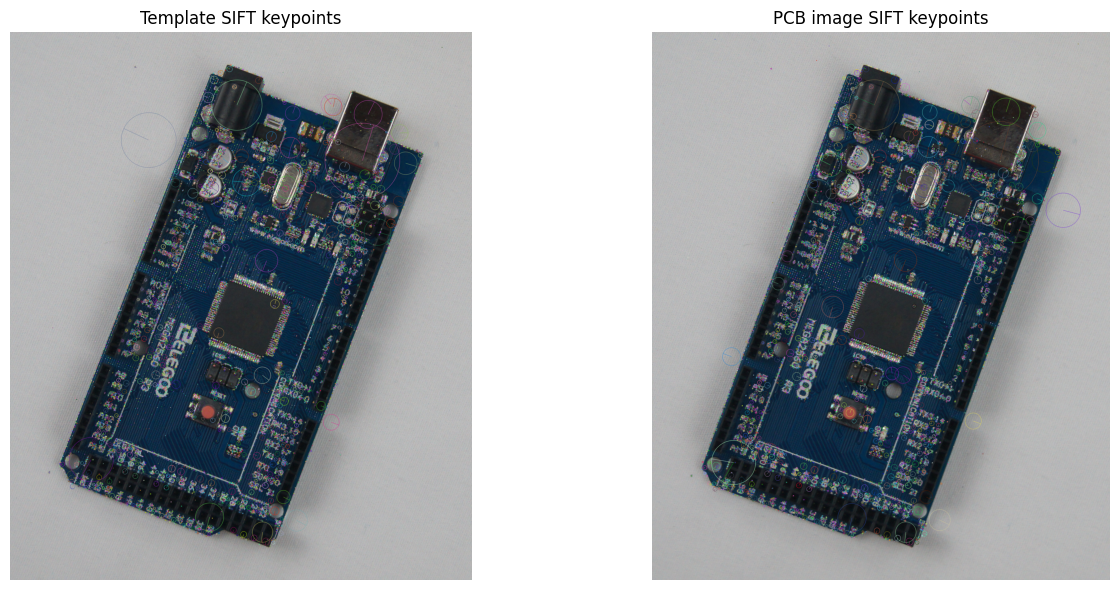

In [12]:
pcb_dir = Path("../a2images/pcbs")
template_path = pcb_dir / "AECC1.jpg"
pcb_path = pcb_dir / "AECC2.jpg"  # Change this to inspect another PCB image.
template_bgr = cv2.imread(str(template_path), cv2.IMREAD_COLOR)
pcb_bgr = cv2.imread(str(pcb_path), cv2.IMREAD_COLOR)
if template_bgr is None or pcb_bgr is None:
    raise FileNotFoundError(f"Could not load {template_path} or {pcb_path}")

template_gray = cv2.cvtColor(template_bgr, cv2.COLOR_BGR2GRAY)
pcb_gray = cv2.cvtColor(pcb_bgr, cv2.COLOR_BGR2GRAY)
sift = cv2.SIFT_create()
template_keypoints, template_descriptors = sift.detectAndCompute(template_gray, None)
pcb_keypoints, pcb_descriptors = sift.detectAndCompute(pcb_gray, None)
print(f"Template SIFT features: {len(template_keypoints)}")
print(f"PCB SIFT features: {len(pcb_keypoints)}")

shown = cv2.drawKeypoints(template_bgr, template_keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
shown_pcb = cv2.drawKeypoints(pcb_bgr, pcb_keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(shown, cv2.COLOR_BGR2RGB))
axes[0].set_title("Template SIFT keypoints")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(shown_pcb, cv2.COLOR_BGR2RGB))
axes[1].set_title("PCB image SIFT keypoints")
axes[1].axis("off")
plt.tight_layout()
plt.show()